In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importación de la función BiAA robusta
from src.Robusted_mxnx1_biAA import robust_biarchetypal_analysis_mxnx1

np.set_printoptions(precision=4, suppress=True)

In [2]:
# -------------------------------------------------------------------------
# 1. GENERACIÓN DE NUEVA MATRIZ DE DATOS (N=150, M=30, k=4, c=3)
# -------------------------------------------------------------------------
rng = np.random.default_rng(100)  # Semilla distinta

N_samples, M_features = 150, 30
k_row_archetypes = 4     # 4 arquetipos de fila
c_col_archetypes = 3     # 3 arquetipos de columna

# Estructura latente limpia
true_Z = rng.uniform(low=0.2, high=0.8, size=(k_row_archetypes, c_col_archetypes))
true_alpha = rng.dirichlet(np.ones(k_row_archetypes), size=N_samples)
true_gamma = rng.dirichlet(np.ones(c_col_archetypes), size=M_features).T

# Matriz sintética base
X_clean = true_alpha @ true_Z @ true_gamma

# Inyección de 25 outliers severos en posiciones aleatorias
X = X_clean.copy()
n_outliers = 25

# Guardamos una matriz máscara de la posición real de los outliers
outlier_mask_real = np.zeros((N_samples, M_features), dtype=bool)

row_idx = rng.integers(0, N_samples, size=n_outliers)
col_idx = rng.integers(0, M_features, size=n_outliers)

for r, c_idx in zip(row_idx, col_idx):
    X[r, c_idx] += rng.uniform(10.0, 20.0)
    outlier_mask_real[r, c_idx] = True

print("="*60)
print("TEST 2: EVALUACIÓN DE DETECCIÓN Y RECUPERACIÓN EN BiAA ROBUSTO")
print("="*60)
print(f"Dimensiones de X: {X.shape}")
print(f"Arquetipos Filas (k): {k_row_archetypes} | Arquetipos Columnas (c): {c_col_archetypes}")
print(f"Celdas totales: {N_samples * M_features} | Outliers inyectados: {n_outliers}")

TEST 2: EVALUACIÓN DE DETECCIÓN Y RECUPERACIÓN EN BiAA ROBUSTO
Dimensiones de X: (150, 30)
Arquetipos Filas (k): 4 | Arquetipos Columnas (c): 3
Celdas totales: 4500 | Outliers inyectados: 25


In [3]:
# -------------------------------------------------------------------------
# 2. EJECUCIÓN DEL ALGORITMO ROBUSTO
# -------------------------------------------------------------------------
print("\nEjecutando Robust BiAA...")

alpha_rob, beta_rob, gamma_rob, theta_rob, Z_rob, W_mat_rob = robust_biarchetypal_analysis_mxnx1(
    X, 
    k=k_row_archetypes, 
    c=c_col_archetypes, 
    max_robust_iter=25, 
    max_inner_iter=60, 
    c_factor=4.685,     # Valor sintonizado estándar para Bisquare
    tol=1e-5, 
    random_state=100, 
    verbose=True
)


Ejecutando Robust BiAA...
Iteración Robust 1/25 | Dif. pesos: 0.132994 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 2/25 | Dif. pesos: 0.160267 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 3/25 | Dif. pesos: 0.006520 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 4/25 | Dif. pesos: 0.002393 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 5/25 | Dif. pesos: 0.000765 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 6/25 | Dif. pesos: 0.000383 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 7/25 | Dif. pesos: 0.000262 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 8/25 | Dif. pesos: 0.000164 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 9/25 | Dif. pesos: 0.000165 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 10/25 | Dif. pesos: 0.000108 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 11/25 | Dif. pesos: 0.000098 | Celdas Outliers (w=0): 25/4500 (0.56%)
Iteración Robust 12/25 | 

In [4]:
# -------------------------------------------------------------------------
# 3. MÉTRICAS DE RENDIMIENTO Y EVALUACIÓN DE DETECCIÓN
# -------------------------------------------------------------------------
X_hat_rob = alpha_rob @ Z_rob @ gamma_rob

# Mascara de outliers detectados por el modelo (donde W == 0)
outlier_mask_detected = (W_mat_rob == 0.0)

# Cálculo de Matriz de Confusión (Verdaderos Positivos, Falsos Positivos, etc.)
tp = np.sum(outlier_mask_real & outlier_mask_detected)
fp = np.sum(~outlier_mask_real & outlier_mask_detected)
fn = np.sum(outlier_mask_real & ~outlier_mask_detected)

precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

# Medida del error de reconstrucción sobre la matriz LIMPIA (evalúa si rescata la estructura real)
error_vs_clean = np.mean((X_clean - X_hat_rob)**2)

print("\n--- RESULTADOS DEL TEST DE VALIDACIÓN ---")
df_metrics = pd.DataFrame([{
    "Outliers Inyectados": n_outliers,
    "Outliers Detectados (w=0)": np.sum(outlier_mask_detected),
    "Verdaderos Positivos (TP)": tp,
    "Falsos Positivos (FP)": fp,
    "Precisión (Precision)": f"{precision:.2%}",
    "Cobertura (Recall)": f"{recall:.2%}",
    "MSE respecto a X_limpia": f"{error_vs_clean:.6f}"
}])

print(df_metrics.to_string(index=False))


--- RESULTADOS DEL TEST DE VALIDACIÓN ---
 Outliers Inyectados  Outliers Detectados (w=0)  Verdaderos Positivos (TP)  Falsos Positivos (FP) Precisión (Precision) Cobertura (Recall) MSE respecto a X_limpia
                  25                         25                         25                      0               100.00%            100.00%                0.006145


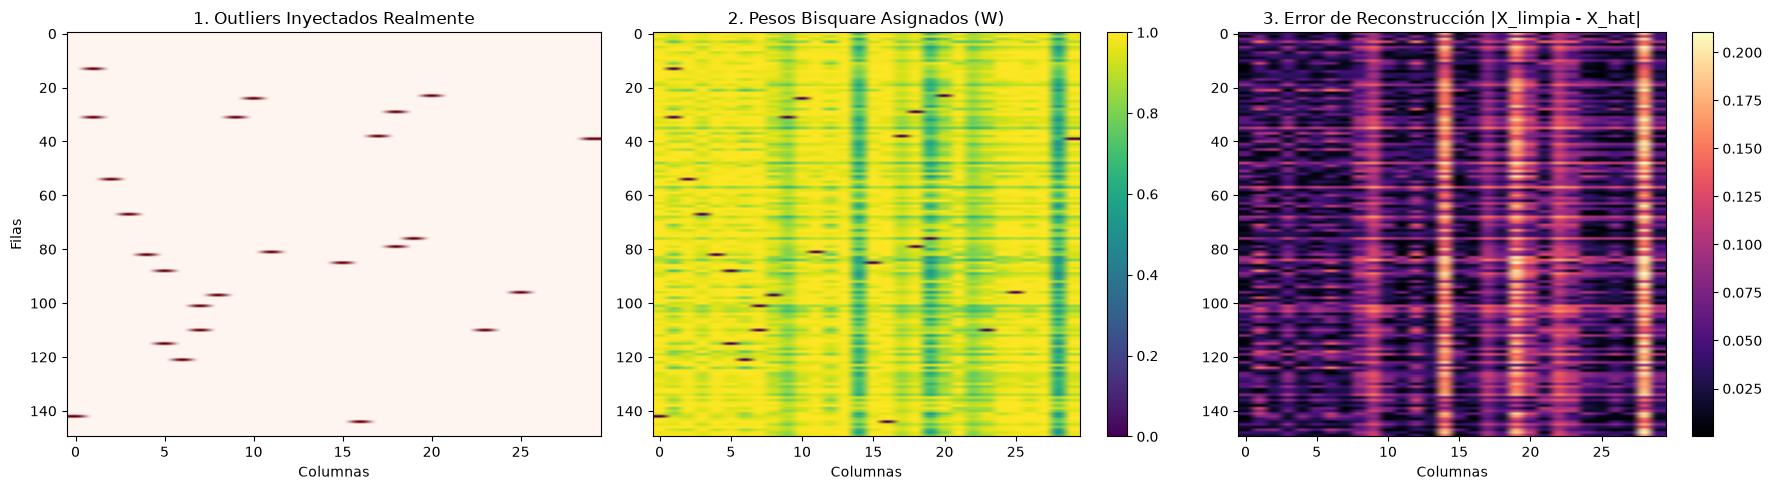

In [5]:
# -------------------------------------------------------------------------
# 4. VISUALIZACIÓN DE COMPARACIÓN DE MÁSCARAS Y PESOS
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Posición real del ruido inyectado
axes[0].imshow(outlier_mask_real, aspect='auto', cmap='Reds')
axes[0].set_title("1. Outliers Inyectados Realmente")
axes[0].set_xlabel("Columnas")
axes[0].set_ylabel("Filas")

# 2. Pesos Bisquare calculados
im1 = axes[1].imshow(W_mat_rob, aspect='auto', cmap='viridis', vmin=0, vmax=1)
axes[1].set_title("2. Pesos Bisquare Asignados (W)")
axes[1].set_xlabel("Columnas")
plt.colorbar(im1, ax=axes[1])

# 3. Diferencia entre matriz limpia original y la reconstrucción robusta
im2 = axes[2].imshow(np.abs(X_clean - X_hat_rob), aspect='auto', cmap='magma')
axes[2].set_title("3. Error de Reconstrucción |X_limpia - X_hat|")
axes[2].set_xlabel("Columnas")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()